# 3. A projection model, tested on a season it never saw

Split by time, the way the model would really be used:

* **Train:** 2021-2023 · **Validate** (pick settings): 2024 · **Test** (touched once, at the end): 2025

Two kinds of score matter for fantasy:
* **MAE**: average miss in points.
* **Start/sit accuracy**: for every pair of same-position players in the same week, how often the one
  projected higher actually scored more. 50% is a coin flip. This is the decision a manager actually makes.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.data import load_player_weeks, load_games
from fantasy.features import FEATURES, TARGET, build_features, model_sample, mingus_projection
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from fantasy.evaluate import score_table, start_sit_pairs

In [2]:
sample = model_sample(pd.read_parquet("../data/features.parquet"))
# Rookies and players new to the sample have no prior season: fill with this season's average and flag it.
sample["has_prior"] = sample.prior_season_avg.notna().astype(int)
sample["prior_fill"] = sample.prior_season_avg.fillna(sample.avg_season)
sample["mingus"] = mingus_projection(sample)

NUM = [f for f in FEATURES if f != "prior_season_avg"] + ["prior_fill", "has_prior"]
X = NUM + ["position"]
train, val, test = (sample[sample.season <= 2023], sample[sample.season == 2024], sample[sample.season == 2025])
print({k: len(v) for k, v in [("train", train), ("val", val), ("test", test)]})

{'train': 7894, 'val': 2622, 'test': 2591}


## Baselines and models

* **Baselines:** last game, last 3 games, season average.
* **Mingus formula:** the site's Start/Sit heuristic, (season avg + last 3) ÷ 2 × matchup factor × Vegas factor.
* **Ridge regression:** a linear model on all features (standardized, regularization strength picked by cross-validation).
* **Gradient boosting:** a tree model that can find interactions (e.g., matchup mattering more for RBs). Trained on absolute
  error, since fantasy scores have a long right tail.

In [3]:
ridge = make_pipeline(
    make_column_transformer((StandardScaler(), NUM), (OneHotEncoder(), ["position"])),
    RidgeCV(alphas=np.logspace(-2, 3, 20)),
).fit(train[X], train[TARGET])

as_cat = lambda d: d[X].assign(position=d.position.astype("category"))  # noqa: E731
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=4, min_samples_leaf=50,
                                    loss="absolute_error", categorical_features=["position"], random_state=0)
hgb.fit(as_cat(train), train[TARGET])

PRED = {"last_game": "Last game", "avg_last3": "Last 3 games", "avg_season": "Season average",
        "mingus": "Mingus formula", "ridge": "Ridge regression", "hgb": "Gradient boosting"}
def predict(d):
    return d.assign(ridge=ridge.predict(d[X]), hgb=hgb.predict(as_cat(d)))

val, test = predict(val), predict(test)
print("Validation (2024)")
score_table(val, list(PRED), TARGET).rename(index=PRED)

Validation (2024)


,MAE,RMSE,r,start/sit acc.
projection,,,,
Last game,7.447,9.591,0.333,0.603
Last 3 games,6.181,7.913,0.426,0.633
Season average,5.822,7.489,0.459,0.647
Mingus formula,5.980,7.726,0.449,0.643
Ridge regression,5.662,7.285,0.498,0.661
Gradient boosting,5.697,7.515,0.486,0.654


Ridge and gradient boosting finish close on validation. Ridge is simpler, easier to explain, and has the better
start/sit accuracy, so it's the pick. **Now the one look at 2025:**

In [4]:
results = score_table(test, list(PRED), TARGET).rename(index=PRED)
results

,MAE,RMSE,r,start/sit acc.
projection,,,,
Last game,7.533,9.948,0.290,0.587
Last 3 games,6.238,8.087,0.400,0.626
Season average,5.871,7.575,0.450,0.641
Mingus formula,6.077,7.885,0.432,0.640
Ridge regression,5.665,7.323,0.488,0.655
Gradient boosting,5.638,7.469,0.474,0.649


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/04_model_comparison.png')

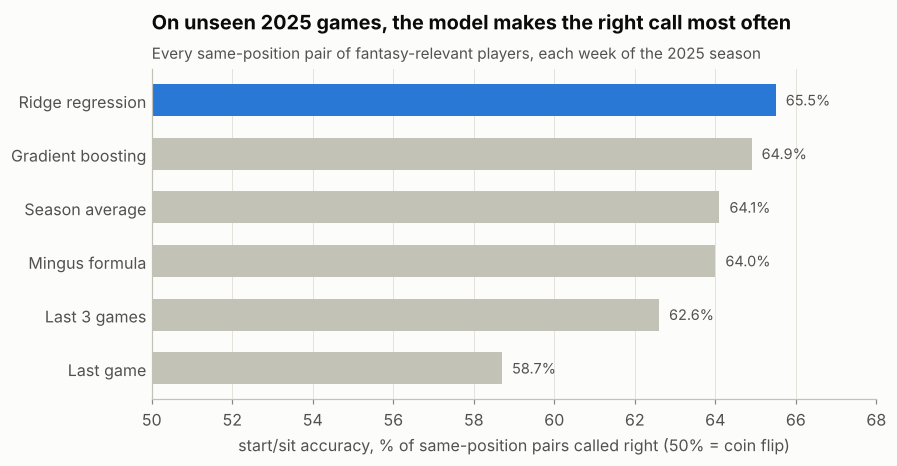

In [5]:
res = results["start/sit acc."].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 3.9))
y = np.arange(len(res))
colors = [P.BLUE if name == "Ridge regression" else P.GREY for name in res.index]
ax.barh(y, res.values * 100, height=0.6, color=colors)
for yi, v in zip(y, res.values * 100):
    ax.text(v + 0.25, yi, f"{v:.1f}%", va="center", color=P.INK_2, fontsize=9.5)
ax.set_yticks(y, res.index)
ax.tick_params(axis="y", length=0)
ax.set_xlim(50, 68)
ax.grid(axis="y", visible=False)
ax.set_xlabel("start/sit accuracy, % of same-position pairs called right (50% = coin flip)")
ax.set_title("On unseen 2025 games, the model makes the right call most often", pad=26)
P.subtitle(ax, "Every same-position pair of fantasy-relevant players, each week of the 2025 season")
P.save(fig, "04_model_comparison")

## How sure should you be?

A 65% hit rate sounds low, but it averages close calls with obvious ones. Split the 2025 decisions by how far
apart the model's two projections were:

In [6]:
pairs = start_sit_pairs(test, "ridge", TARGET)
bins = [0, 1, 2, 4, 6, 10, np.inf]
labels = ["< 1", "1-2", "2-4", "4-6", "6-10", "10+"]
by_gap = pairs.groupby(pd.cut(pairs.gap, bins, labels=labels, right=False), observed=True).correct.agg(["mean", "size"])
by_gap

,mean,size
gap,,
< 1,0.523,10402
1-2,0.559,9755
2-4,0.628,16521
4-6,0.709,12245
6-10,0.778,11203
10+,0.875,3177


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/05_confidence_by_gap.png')

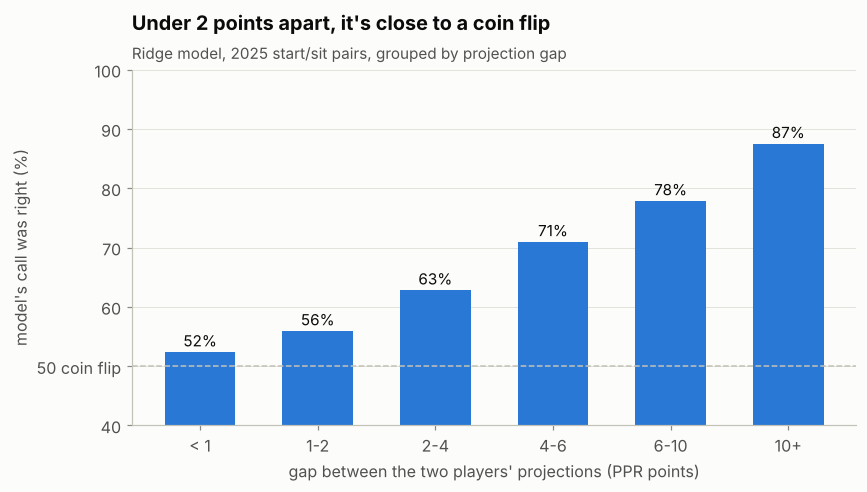

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(by_gap))
ax.bar(x, by_gap["mean"] * 100, width=0.6, color=P.BLUE)
for xi, v, n in zip(x, by_gap["mean"] * 100, by_gap["size"]):
    ax.text(xi, v + 1, f"{v:.0f}%", ha="center", color=P.INK, fontsize=10)
ax.axhline(50, color=P.GREY, linewidth=1, linestyle="--")
ax.set_xticks(x, labels)
ax.set_yticks([40, 50, 60, 70, 80, 90, 100], ["40", "50 coin flip", "60", "70", "80", "90", "100"])
ax.set_ylim(40, 100)
ax.grid(axis="x", visible=False)
ax.set_xlabel("gap between the two players' projections (PPR points)")
ax.set_ylabel("model's call was right (%)")
ax.set_title("Under 2 points apart, it's close to a coin flip", pad=26)
P.subtitle(ax, "Ridge model, 2025 start/sit pairs, grouped by projection gap")
P.save(fig, "05_confidence_by_gap")

## What the model leans on

Standardized ridge coefficients: points added per one-standard-deviation change in each feature, with
everything else held fixed.

PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/06_coefficients.png')

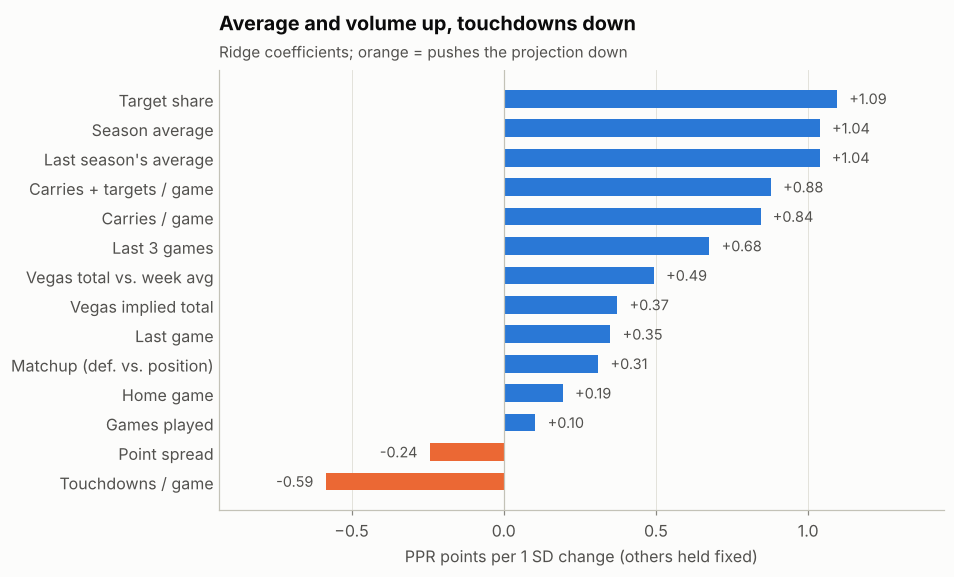

In [8]:
coef = pd.Series(ridge[-1].coef_, index=ridge[0].get_feature_names_out())
coef = coef[coef.index.str.startswith("standardscaler")]
coef.index = coef.index.str.replace("standardscaler__", "")
NAMES = {"avg_season": "Season average", "prior_fill": "Last season's average", "target_share_avg": "Target share",
         "opps_per_game": "Carries + targets / game", "carries_per_game": "Carries / game", "avg_last3": "Last 3 games",
         "implied_factor": "Vegas total vs. week avg", "implied_total": "Vegas implied total", "last_game": "Last game",
         "def_factor": "Matchup (def. vs. position)", "home": "Home game", "games_prior": "Games played",
         "has_prior": "Has a prior season", "targets_per_game": "Targets / game", "spread": "Point spread",
         "tds_per_game": "Touchdowns / game"}
coef = coef.rename(NAMES).sort_values()
coef = coef[coef.abs() >= 0.1]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(coef))
ax.barh(y, coef.values, height=0.6, color=[P.BLUE if v > 0 else P.ORANGE for v in coef.values])
for yi, v in zip(y, coef.values):
    ax.text(v + (0.04 if v > 0 else -0.04), yi, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right",
            color=P.INK_2, fontsize=9.5)
ax.axvline(0, color=P.GREY, linewidth=0.8)
ax.set_yticks(y, coef.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(coef.min() - 0.35, coef.max() + 0.35)
ax.set_xlabel("PPR points per 1 SD change (others held fixed)")
ax.set_title("Average and volume up, touchdowns down", pad=26)
P.subtitle(ax, "Ridge coefficients; orange = pushes the projection down")
P.save(fig, "06_coefficients")

Two things stand out:

1. **Last season counts as much as this season.** Its weight is about the same as the season-to-date average.
2. **Touchdowns per game is negative.** Holding points and volume fixed, a player who has scored a lot of touchdowns
   is projected *lower*. That's regression to the mean, the same thing the reliability chart in notebook 2 showed.

## Takeaways

* Start/sit is noisy: even the best projection here gets about 2 of 3 calls right. Under a ~2-point gap, it's a toss-up.
* Weight the full season (and last season early on) over the last few games.
* Volume and target share are stickier than touchdowns. Fade TD-driven hot streaks.
* Matchup and Vegas adjustments help a little. The data supports a nudge of about ±5%, not ±20%.

### Error by position (2025)

In [9]:
test.groupby("position").apply(lambda d: pd.Series({
    "MAE season avg": (d.avg_season - d[TARGET]).abs().mean(),
    "MAE ridge": (d.ridge - d[TARGET]).abs().mean(),
    "rows": len(d)})).round(2)

,MAE season avg,MAE ridge,rows
position,,,
QB,6.95,6.70,414.0
RB,6.03,5.84,670.0
TE,5.07,4.82,456.0
WR,5.70,5.51,1051.0
